In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [141]:
df=pd.read_csv('pargi_voters_1000_natural_complete.csv')
df.shape

(1000, 16)

In [142]:
df.head()

,name,voterid,age,gender,address,state,district_number,district_name,constituency_name,constituency_number,polling_station_id,polling_station_name,pincode,household_size,distance_from_assigned_polling_booth_km,voted_status
0,Aditya Pasupuleti,DUMMY-PRG-0522,51,Male,"Sample Nagar B, House 0621, Pargi (Dummy Address)",Telangana,15,Vikarabad,Pargi,54,PRG-PS-002,Govt High School 53,501501,5,1.51,1
1,Akhil Challa,DUMMY-PRG-0738,27,Male,"Demo Street H, House 0837, Pargi (Dummy Address)",Telangana,15,Vikarabad,Pargi,54,PRG-PS-008,Government Junior College 74,501501,5,1.11,1
2,Akhil Chintala,DUMMY-PRG-0741,65,Female,"Dummy Colony A, House 0840, Pargi (Dummy Address)",Telangana,15,Vikarabad,Pargi,54,PRG-PS-001,Govt Primary School 75,501501,5,1.82,1
3,Abhinav Samala,DUMMY-PRG-0661,54,Female,"Dummy Colony A, House 0760, Pargi (Dummy Address)",Telangana,15,Vikarabad,Pargi,54,PRG-PS-001,Govt Primary School 67,501501,4,2.60,1
4,Anil Tummala,DUMMY-PRG-0412,67,Male,"Sample Nagar B, House 0511, Pargi (Dummy Address)",Telangana,15,Vikarabad,Pargi,54,PRG-PS-002,Govt High School 42,501501,6,4.60,0


In [143]:
from sklearn.preprocessing import LabelEncoder
lb=LabelEncoder()

In [144]:
df['voted_status']=lb.fit_transform(df['voted_status'])

In [145]:
df.head()

,name,voterid,age,gender,address,state,district_number,district_name,constituency_name,constituency_number,polling_station_id,polling_station_name,pincode,household_size,distance_from_assigned_polling_booth_km,voted_status
0,Aditya Pasupuleti,DUMMY-PRG-0522,51,Male,"Sample Nagar B, House 0621, Pargi (Dummy Address)",Telangana,15,Vikarabad,Pargi,54,PRG-PS-002,Govt High School 53,501501,5,1.51,1
1,Akhil Challa,DUMMY-PRG-0738,27,Male,"Demo Street H, House 0837, Pargi (Dummy Address)",Telangana,15,Vikarabad,Pargi,54,PRG-PS-008,Government Junior College 74,501501,5,1.11,1
2,Akhil Chintala,DUMMY-PRG-0741,65,Female,"Dummy Colony A, House 0840, Pargi (Dummy Address)",Telangana,15,Vikarabad,Pargi,54,PRG-PS-001,Govt Primary School 75,501501,5,1.82,1
3,Abhinav Samala,DUMMY-PRG-0661,54,Female,"Dummy Colony A, House 0760, Pargi (Dummy Address)",Telangana,15,Vikarabad,Pargi,54,PRG-PS-001,Govt Primary School 67,501501,4,2.60,1
4,Anil Tummala,DUMMY-PRG-0412,67,Male,"Sample Nagar B, House 0511, Pargi (Dummy Address)",Telangana,15,Vikarabad,Pargi,54,PRG-PS-002,Govt High School 42,501501,6,4.60,0


In [146]:
df1=df[['age','distance_from_assigned_polling_booth_km']]

Text(0.5, 1.0, 'Age vs Distance from Polling Booth')

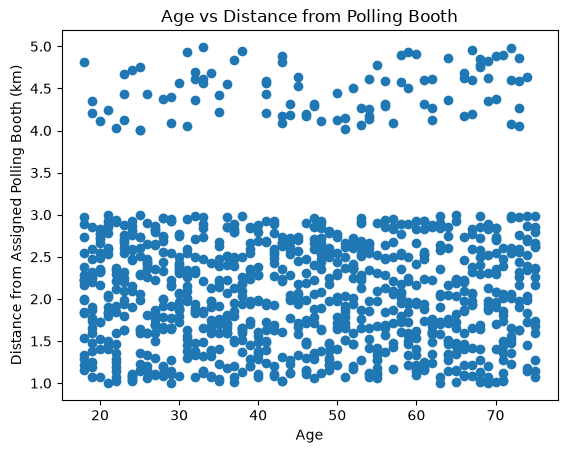

In [147]:
plt.scatter(df1['age'],df1['distance_from_assigned_polling_booth_km'])
plt.xlabel('Age')
plt.ylabel('Distance from Assigned Polling Booth (km)')
plt.title('Age vs Distance from Polling Booth')

In [148]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [149]:
X=df1.iloc[:,:].values
X = StandardScaler().fit_transform(X)
km=KMeans(n_clusters=2)

In [150]:
y_means=km.fit_predict(X)

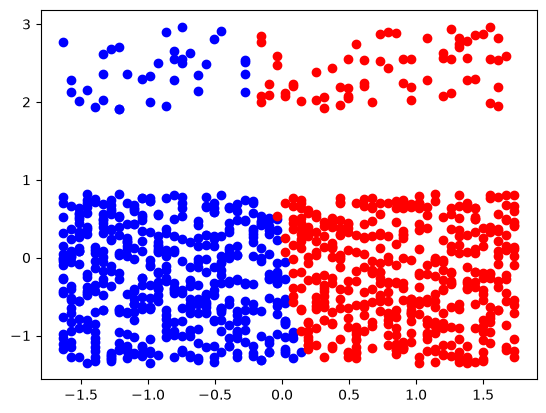

In [151]:
plt.scatter(X[y_means==0,0],X[y_means==0,1],color='blue',label='Cluster 1')
plt.scatter(X[y_means==1,0],X[y_means==1,1],color='red',label='Cluster 2')

In [163]:
from sklearn.cluster import AgglomerativeClustering
c=AgglomerativeClustering(n_clusters=2,metric='euclidean',linkage='complete')
labels_=c.fit_predict(X[:,:2])
labels_

array([0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,

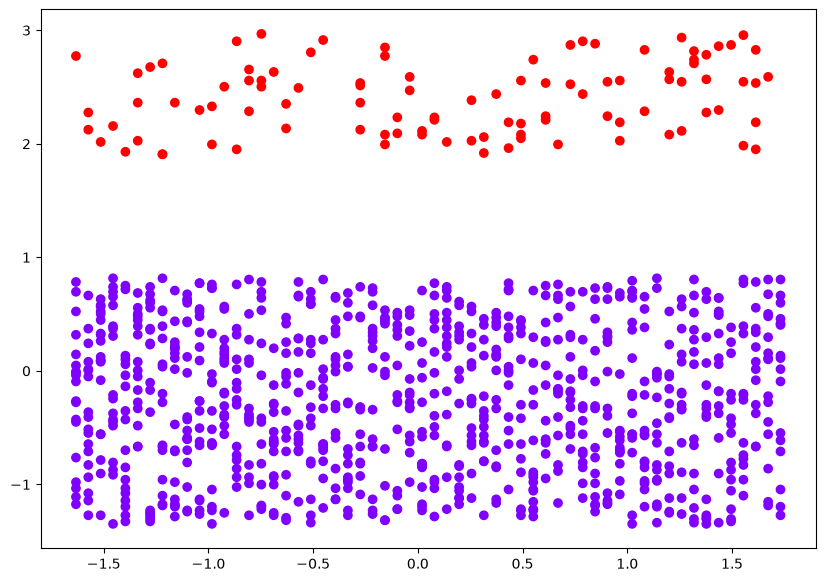

In [164]:
plt.figure(figsize=(10,7))
plt.scatter(X[:,0],X[:,1],c=c.labels_,cmap='rainbow')

In [154]:
from sklearn.cluster import DBSCAN

In [155]:
db = DBSCAN(eps=0.5, min_samples=4)

db.fit(X)
db.labels_

array([0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,

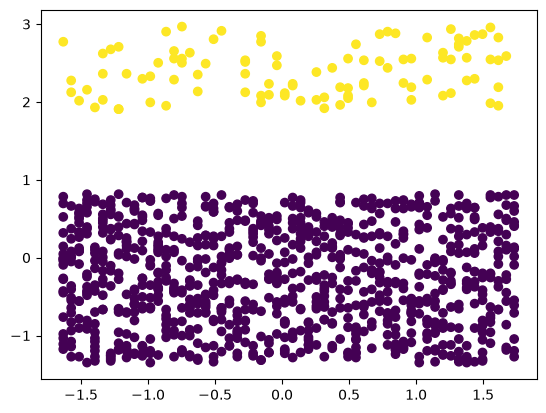

In [156]:

dbscan = DBSCAN(eps=0.7, min_samples=5)
clusters = dbscan.fit_predict(X)

# Plotting
plt.scatter(X[:, 0], X[:, 1], c=clusters)


In [157]:
df.columns

Index(['name', 'voterid', 'age', 'gender', 'address', 'state',
       'district_number', 'district_name', 'constituency_name',
       'constituency_number', 'polling_station_id', 'polling_station_name',
       'pincode', 'household_size', 'distance_from_assigned_polling_booth_km',
       'voted_status'],
      dtype='str')

In [158]:
df.sample()

,name,voterid,age,gender,address,state,district_number,district_name,constituency_name,constituency_number,polling_station_id,polling_station_name,pincode,household_size,distance_from_assigned_polling_booth_km,voted_status
64,Ajay Yalamanchili,DUMMY-PRG-0605,47,Female,"Test Residency E, House 0704, Pargi (Dummy Add...",Telangana,15,Vikarabad,Pargi,54,PRG-PS-005,MPPS 61,501501,4,2.86,0
